# 04 · Hillstrom e-mail test: arms, heterogeneity, CUPED, uplift
This analysis follows `docs/pre_analysis_plan_hillstrom.md`. It covers a marketing experiment with a two-week window, so it says nothing about retention.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
FIG = ROOT / "reports" / "figures"

In [2]:
from src.analysis import hillstrom as hs
r = hs.run()
print(r['n']); r['srm']

{'Womens E-Mail': 21387, 'Mens E-Mail': 21307, 'No E-Mail': 21306}


{'chi2': 0.20253125000000002,
 'p_value': 0.9036929575604196,
 'srm_detected': False}

## Arm vs control (Holm across the two arms)

In [3]:
rows=[]
for a in r['arm_effects']:
    for m in ('conversion','visit'):
        x=a[m]; rows.append({'arm':a['arm'],'metric':m,'control':x['rate_control'],'treatment':x['rate_treatment'],'diff_pp':100*x['abs_diff'],'ci_low_pp':100*x['ci_low'],'ci_high_pp':100*x['ci_high'],'p_holm':x['p_holm']})
    s=a['spend']; rows.append({'arm':a['arm'],'metric':'spend (bootstrap)','control':s['mean_control'],'treatment':s['mean_treatment'],'diff_pp':s['estimate'],'ci_low_pp':s['ci_low'],'ci_high_pp':s['ci_high']})
pd.DataFrame(rows)

,arm,metric,control,treatment,diff_pp,ci_low_pp,ci_high_pp,p_holm
0,Mens E-Mail,conversion,0.0057,0.0125,0.6805,0.5014,0.8641,3.0464e-13
1,Mens E-Mail,visit,0.1062,0.1828,7.6590,6.9953,8.3227,1.1370e-111
2,Mens E-Mail,spend (bootstrap),0.6528,1.4226,0.7698,0.4909,1.0560,NaN
3,Womens E-Mail,conversion,0.0057,0.0088,0.3111,0.1502,0.4745,1.5711e-04
4,Womens E-Mail,visit,0.1062,0.1514,4.5233,3.8894,5.1574,3.1824e-44
5,Womens E-Mail,spend (bootstrap),0.6528,1.0772,0.4244,0.1699,0.6845,NaN


## Interaction tests first (likelihood-ratio, Holm across 12 per outcome)

In [4]:
display(r['interaction_tests_conversion']); display(r['interaction_tests_visit'])

,outcome,arm,covariate,lr_stat,dof,p_value,p_holm,p_bh
0,conversion,Mens E-Mail,recency_grp,5.7184,3,0.1261,1.0000,0.3027
1,conversion,Mens E-Mail,history_segment,3.3628,6,0.7621,1.0000,0.8704
2,conversion,Mens E-Mail,newbie,4.9049,1,0.0268,0.2946,0.1311
3,conversion,Mens E-Mail,zip_code,1.9165,2,0.3836,1.0000,0.6575
4,conversion,Mens E-Mail,channel,0.4517,2,0.7978,1.0000,0.8704
5,conversion,Mens E-Mail,product_line,0.6208,2,0.7331,1.0000,0.8704
6,conversion,Womens E-Mail,recency_grp,3.6280,3,0.3045,1.0000,0.6091
7,conversion,Womens E-Mail,history_segment,13.7327,6,0.0328,0.3277,0.1311
8,conversion,Womens E-Mail,newbie,10.3878,1,0.0013,0.0152,0.0152
9,conversion,Womens E-Mail,zip_code,0.2613,2,0.8775,1.0000,0.8775


,outcome,arm,covariate,lr_stat,dof,p_value,p_holm,p_bh
0,visit,Mens E-Mail,recency_grp,3.6741,3,2.9888e-01,1.0000e+00,3.6864e-01
1,visit,Mens E-Mail,history_segment,5.1459,6,5.2524e-01,1.0000e+00,5.2524e-01
2,visit,Mens E-Mail,newbie,12.2310,1,4.7001e-04,4.7001e-03,1.8801e-03
3,visit,Mens E-Mail,zip_code,7.1749,2,2.7668e-02,1.9368e-01,5.5336e-02
4,visit,Mens E-Mail,channel,4.6168,2,9.9422e-02,5.9653e-01,1.7044e-01
5,visit,Mens E-Mail,product_line,2.3605,2,3.0720e-01,1.0000e+00,3.6864e-01
6,visit,Womens E-Mail,recency_grp,9.9326,3,1.9148e-02,1.5318e-01,4.5955e-02
7,visit,Womens E-Mail,history_segment,10.1732,6,1.1755e-01,5.9653e-01,1.7632e-01
8,visit,Womens E-Mail,newbie,16.2686,1,5.4967e-05,6.0464e-04,3.2980e-04
9,visit,Womens E-Mail,zip_code,10.6190,2,4.9445e-03,4.4500e-02,1.4833e-02


## Subgroup effects on conversion (Holm main, BH 10% sensitivity)

{'n_examined': 44, 'n_tested': 44, 'n_survive_holm': 17, 'n_survive_bh10': 32, 'n_nominal_p05': 32}


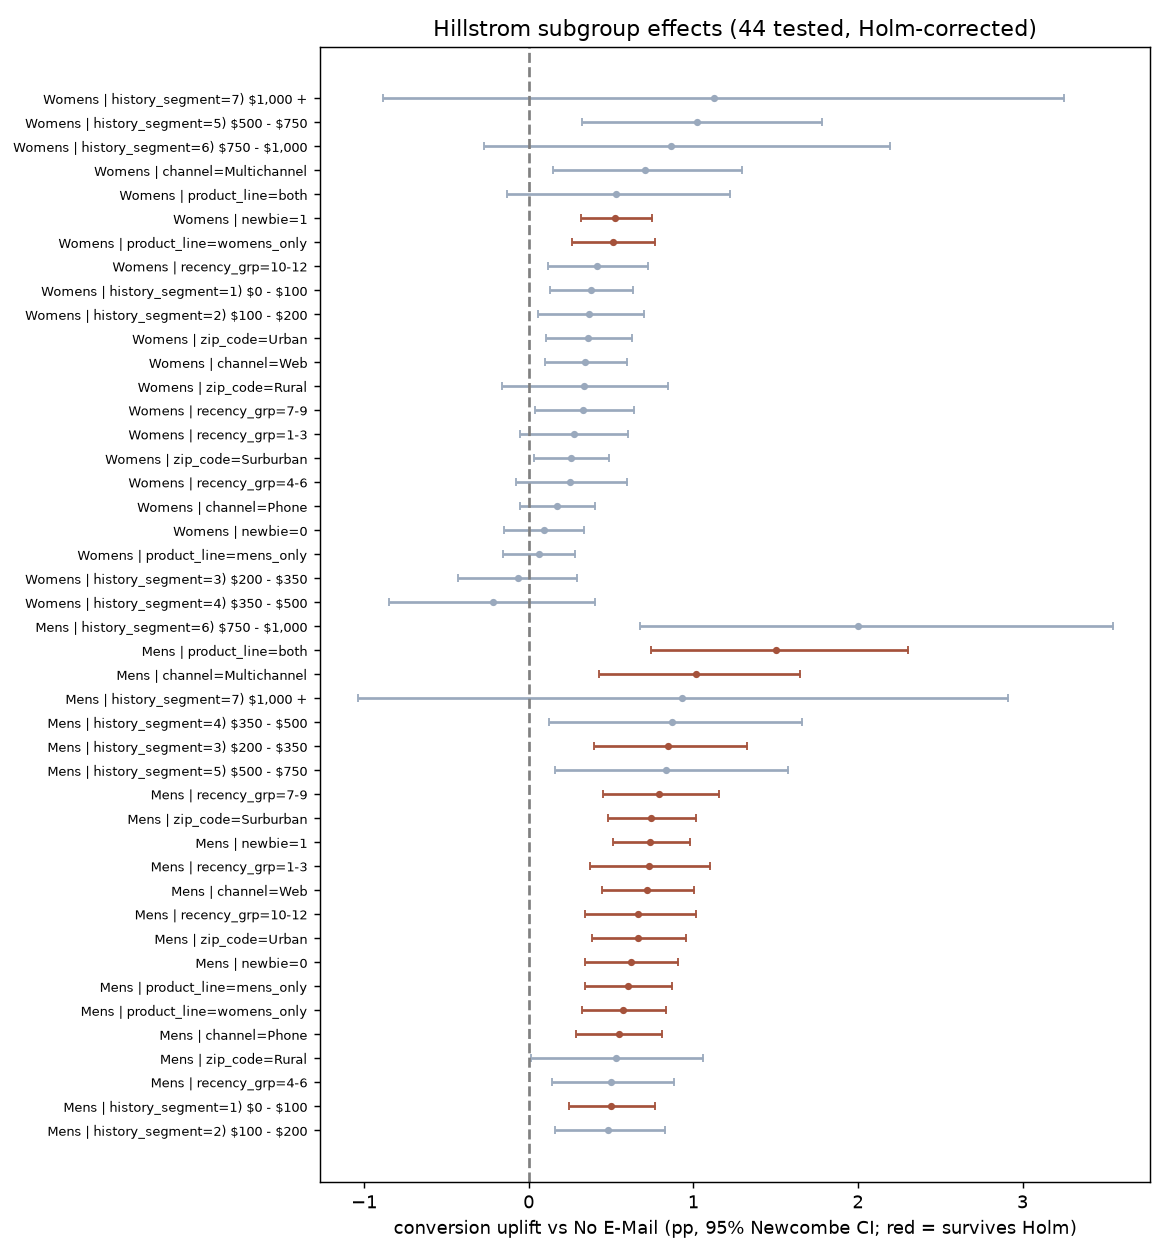

In [5]:
print(r['subgroup_summary'])
display(Image(FIG / 'hillstrom_subgroups.png'))

**Reading.** 44 subgroup effects were examined. 32 are nominally significant, and 17 survive Holm, most of them Mens-arm subgroups that share the strong overall effect. The only interaction that survives Holm for conversion is **Womens e-mail × newbie**: the Womens e-mail works for new customers and shows no detectable effect for existing ones. The a priori expectation (each e-mail works best for buyers of its own product line) is **not** supported for conversion. For visits, product line interacts strongly with the Womens e-mail.

## CUPED on spend (covariate: past-year spend)

In [6]:
pd.DataFrame([{ 'arm': c['arm'], 'theta': c['theta'], 'variance_reduction': c['variance_reduction'], 'ci_width_ratio': c['ci_width_ratio']} for c in r['cuped_spend']])

,arm,theta,variance_reduction,ci_width_ratio
0,Mens E-Mail,0.0013,0.0004,1.0008
1,Womens E-Mail,0.0013,0.0004,0.9998


CUPED achieves almost no variance reduction (< 0.1%), because past-year spend is barely correlated with spend in a two-week window. That result is reported as it came out.

## Uplift model: EXPLORATORY
T-learner (gradient boosting), visit outcome, Womens e-mail vs control, 50% holdout. The economics are a scenario with assumed values.

{'label': 'EXPLORATORY',
 'arm': 'Womens E-Mail',
 'outcome': 'visit',
 'holdout_n': 21347,
 'qini_auc_normalized': 0.002998654012824873,
 'uplift_top_share': 0.06978325750794273,
 'uplift_all': 0.04522602783338689,
 'top_share': 0.3,
 'economics': {'label': 'SCENARIO - assumed cost and value',
  'assumptions': {'cost_per_email_usd': 0.1,
   'value_per_incremental_visit_usd': 1.0,
   'customers': 100000},
  'email_everyone_net': np.float64(-5477.397216661311),
  'email_top_30pct_net': np.float64(-906.5022747617182)}}

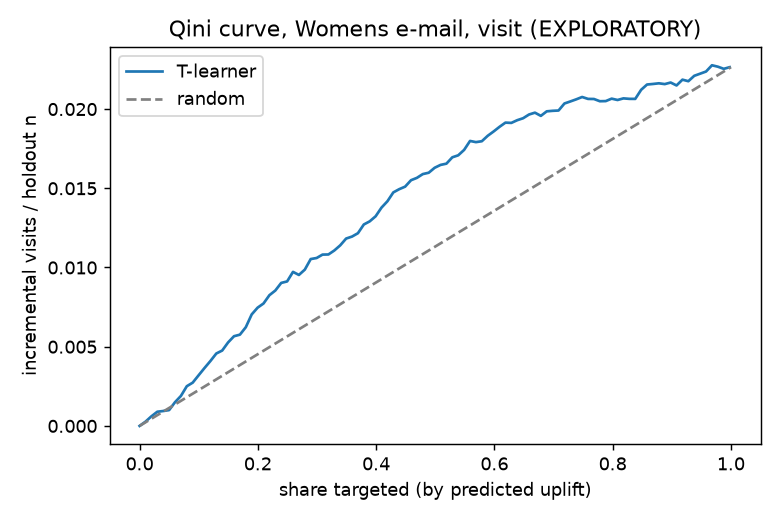

In [7]:
display({k: v for k, v in r['uplift'].items() if k != 'qini_curve'}); display(Image(FIG / 'hillstrom_qini.png'))